# Black-Litterman Portfolio with LSTM + SVR Investor's Views

**Architecture B** — one multi-output LSTM per stock (predicts all 8 indicators at once),
then an SVR decodes the predicted indicators into a price forecast. The forecast becomes
the Black-Litterman view (Q), and the model's error sets the view's uncertainty (Ω).

```
yfinance OHLCV → 8 indicators → 30-day windows
   → LSTM (1 per stock, 8 outputs) → SVR (indicators → price)
   → views Q + Ω → Black-Litterman w*  → backtest vs SPY
```

This notebook **reuses the verified `bl_lstm_views/src` modules** (so the heavy logic is
tested), and keeps the project's two refinements over the raw design doc:

- **Stationary price target** — the SVR predicts `close / SMA₃₀(close) − 1`, not the raw
  price level, so an RBF model can't be wrecked by the 2010→2025 price trend.
- **Long-only + capped, renormalised weights** and the **no-views ⇒ w\*=w_mkt** identity.

> Research scaffold, **not** a profitable strategy — backtest numbers are illustrative.
> See `README.md` for the full caveats.

In [1]:
# Fresh setup:  pip install -r requirements.txt   (numpy pandas scikit-learn yfinance torch)
import os, sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.getcwd())          # run this notebook from the bl_lstm_views/ folder
from src import constants as C
from src import fetch_data, black_litterman as bl
from src.indicators import add_indicators
from src.preprocessing import build_stock_dataset
from src.lstm_model import LSTMRegressor, get_device, train_stock_model, predict_indicators
from src.svr_model import train_close_svr, predict_price, train_fit_mse
from src.views import compose_view, assemble_package, write_views_json
from src.backtest import run_backtest

TICKERS    = ["RKLB","AMAT", "CRWD", "IONQ", "RBRK", "LLY", "EOSE", "ASML", "ELV", "PLTR", "OKLO"]
EPOCHS     = 400
MIN_WEIGHT = 0.01      
MAX_WEIGHT = 0.40                                    
device     = get_device(os.environ.get("BL_DEVICE", "auto"))

pct = lambda x: np.round(np.asarray(x, float) * 100, 2)
print("torch", torch.__version__, "| device:", device.type)
print("tickers:", TICKERS, "| epochs:", EPOCHS)

torch 2.12.1 | device: mps
tickers: ['RKLB', 'AMAT', 'CRWD', 'IONQ', 'RBRK', 'LLY', 'EOSE', 'ASML', 'ELV', 'PLTR', 'OKLO'] | epochs: 400


## Step 1 — Fetch Data
Daily OHLCV + market caps from yfinance (cached to `output/cache/`).

In [2]:
data   = fetch_data.fetch(TICKERS)
prices = data["prices"]
caps   = data["market_caps"]
bench  = fetch_data.download_prices(C.BENCHMARK, C.DATA_START, C.DATA_END)
bench_close = bench["close"] if bench is not None else None

df_summary = pd.DataFrame({t: {"Days": len(df), "Market Caps": round(caps.get(t, 0) / 1e9, 2)}
                           for t, df in prices.items()}).T

total_caps = df_summary["Market Caps"].sum()
df_summary["W_mkt"] = round(df_summary["Market Caps"] / total_caps, 4)
df_summary.loc["Total"] = ["", total_caps, df_summary["W_mkt"].sum()]
df_summary

  ↗  Fetching ['RKLB', 'AMAT', 'CRWD', 'IONQ', 'RBRK', 'LLY', 'EOSE', 'ASML', 'ELV', 'PLTR', 'OKLO']  (2010-01-01 → 2026-06-24)
  ✅  RKLB: 1399 daily bars
  ✅  AMAT: 4142 daily bars
  ✅  CRWD: 1767 daily bars
  ✅  IONQ: 1373 daily bars
  ✅  RBRK: 541 daily bars
  ✅  LLY: 4142 daily bars
  ✅  EOSE: 1415 daily bars
  ✅  ASML: 4142 daily bars
  ✅  ELV: 4142 daily bars
  ✅  PLTR: 1438 daily bars
  ✅  OKLO: 1245 daily bars
  ✅  SPY: 4142 daily bars


,Days,Market Caps,W_mkt
RKLB,1399.0,53.37,0.0193
AMAT,4142.0,467.62,0.1688
CRWD,1767.0,171.33,0.0618
IONQ,1373.0,20.01,0.0072
RBRK,541.0,15.34,0.0055
LLY,4142.0,996.31,0.3596
EOSE,1415.0,2.06,0.0007
ASML,4142.0,679.40,0.2452
ELV,4142.0,83.39,0.0301
PLTR,1438.0,272.09,0.0982


## Step 2 — Compute Indicators (8)
MACD · RSI · squeeze_on · BB_width · KC_width · sq_momentum · OBV · Hilbert — all pure pandas/numpy (`src/indicators.py`).

In [3]:
sample = add_indicators(prices[TICKERS[0]])[C.FEATURES].dropna()
print(f"{TICKERS[0]}: {sample.shape[0]} rows x {sample.shape[1]} features")
sample.tail()

RKLB: 1369 rows x 8 features


Price,macd,rsi,squeeze_on,bb_width,kc_width,sq_momentum,obv,hilbert
Date,,,,,,,,
2026-06-16,-0.426203,45.335988,0,59.340184,33.456836,-18.053436,-0.039315,30.0
2026-06-17,-0.774367,47.326375,0,60.547442,32.356183,-17.109809,-0.021842,30.0
2026-06-18,-1.097353,46.919962,0,60.692143,31.728929,-15.552496,-0.058909,30.0
2026-06-22,-1.892314,43.170365,0,62.967816,31.821412,-16.412938,-0.071629,30.0
2026-06-23,-2.906004,40.572879,0,64.384935,30.746516,-17.015826,-0.079770,30.0


## Step 3 — Preprocess
Train-only MinMax scaling, 30-day windows, 5-day-ahead targets (`src/preprocessing.py`). Split: train ≤2023 · val 2024 · test 2025.

In [4]:
stock_data = {t: build_stock_dataset(t, prices[t]) for t in TICKERS if t in prices}
sd0 = stock_data[TICKERS[0]]; w = sd0.windows
print("X:", w["X"].shape, " Y:", w["Y"].shape,
      " (window=", C.TIME_WINDOW, ", features=", C.LSTM_OUTPUTS, ", horizon=", C.HORIZON, ")")
print("windows  train/val/test:", int(w["train"].sum()), int(w["val"].sum()), int(w["test"].sum()))

X: (1335, 30, 8)  Y: (1335, 8)  (window= 30 , features= 8 , horizon= 5 )
windows  train/val/test: 934 267 134


## Step 4 — Train LSTM (Architecture B)
One 4-layer LSTM per stock, `Dense(60 → 8)` multi-output head. Adam(5e-3), dropout 0.30, val-driven early stopping + LR plateau.

In [5]:
demo = LSTMRegressor()
print(demo)
print(f"\n{sum(p.numel() for p in demo.parameters()):,} params per stock"
      f"  ->  {len(stock_data)} models total (Architecture B)")

LSTMRegressor(
  (lstm): LSTM(8, 60, num_layers=4, batch_first=True, dropout=0.3)
  (head): Linear(in_features=60, out_features=8, bias=True)
)

105,128 params per stock  ->  11 models total (Architecture B)


In [6]:
lstm_results = {}
for t, sd in stock_data.items():
    print(f"\nTraining {t} ...")
    lstm_results[t] = train_stock_model(sd, epochs=EPOCHS, device=device)
print("\nLSTM training done.")

pd.DataFrame({t: {"val_MSE": round(r["val_mse"], 4),
                  "test_MSE_mean": round(float(np.nanmean(r["mse_test"])), 4)}
              for t, r in lstm_results.items()}).T


Training RKLB ...
      [RKLB] epoch  50 | train 0.0351 | val 0.5999
      [RKLB] epoch 100 | train 0.0225 | val 0.5150
      [RKLB] epoch 150 | train 0.0292 | val 0.4912
      [RKLB] epoch 200 | train 0.0249 | val 0.4833
      [RKLB] early stop at epoch 216 (best val 0.4813)

Training AMAT ...
      [AMAT] epoch  50 | train 0.0159 | val 0.1805
      [AMAT] epoch 100 | train 0.0189 | val 0.1142
      [AMAT] epoch 150 | train 0.0237 | val 0.0895
      [AMAT] epoch 200 | train 0.0158 | val 0.0883
      [AMAT] early stop at epoch 224 (best val 0.0843)

Training CRWD ...
      [CRWD] epoch  50 | train 0.0285 | val 0.2522
      [CRWD] epoch 100 | train 0.0197 | val 0.1775
      [CRWD] epoch 150 | train 0.0217 | val 0.1396
      [CRWD] epoch 200 | train 0.0160 | val 0.1232
      [CRWD] epoch 250 | train 0.0157 | val 0.1132
      [CRWD] epoch 300 | train 0.0175 | val 0.1080
      [CRWD] epoch 350 | train 0.0092 | val 0.1018
      [CRWD] epoch 400 | train 0.0082 | val 0.0998

Training IONQ ..

,val_MSE,test_MSE_mean
RKLB,0.4813,4.0376
AMAT,0.0843,0.5441
CRWD,0.0975,0.2302
IONQ,0.2188,0.1989
RBRK,0.1491,0.2165
LLY,0.4430,2.0322
EOSE,0.0492,0.3569
ASML,0.1366,0.3928
ELV,0.0489,0.0477
PLTR,0.6881,0.6642


## Step 5 — Train SVR
SVR(RBF, C=5, ε=0.01) maps scaled indicators → `close/SMA₃₀ − 1` (the stationary target). At inference it decodes the LSTM's forecast into a price.

In [7]:
svr_models = {t: train_close_svr(sd) for t, sd in stock_data.items()}
pd.DataFrame({t: {"SVR_fit_MSE": round(train_fit_mse(svr_models[t], stock_data[t]), 5)}
              for t in stock_data}).T

,SVR_fit_MSE
RKLB,0.00057
AMAT,0.00019
CRWD,0.00067
IONQ,0.00098
RBRK,0.00010
LLY,0.00007
EOSE,0.00288
ASML,0.00019
ELV,0.00013
PLTR,0.00114


## Step 6 — Black-Litterman
Compose each stock's view (`compose_view`), build Π, μ_BL and the optimal weights w\* (`src/black_litterman.py`), and export `views.json`.

In [8]:
per_stock = {t: compose_view(stock_data[t], lstm_results[t], svr_models[t]) for t in stock_data}
views     = assemble_package(per_stock)
tickers   = views["tickers"]

panel = pd.DataFrame({t: pd.Series(stock_data[t].close_raw,
                      index=pd.DatetimeIndex(stock_data[t].dates).normalize())
                      for t in tickers}).dropna()
sigma = bl.covariance(panel.pct_change().dropna().to_numpy())
w_mkt = bl.market_weights(np.array([caps.get(t, 0) for t in tickers]))
res   = bl.solve(sigma, w_mkt, P=views["P"], Q=views["Q"], omega=views["omega"], max_weight=MAX_WEIGHT)

write_views_json(views)
print("views.json ->", os.path.relpath(C.VIEWS_JSON))

pd.DataFrame({
    "view_q_5d_%": pct([per_stock[t]["q_horizon"] for t in tickers]),
    "Pi_ann_%":    pct(res["pi"]),
    "muBL_ann_%":  pct(res["mu_bl"]),
    "w_mkt_%":     pct(w_mkt),
    "w_star_%":    pct(res["w_star"]),
    "dW_%":        pct(res["w_star"] - w_mkt),
}, index=tickers)

views.json -> output/views.json


,view_q_5d_%,Pi_ann_%,muBL_ann_%,w_mkt_%,w_star_%,dW_%
RKLB,13.36,29.78,29.41,1.93,2.02,0.10
AMAT,-14.67,29.32,28.80,16.88,16.48,-0.40
CRWD,-3.19,18.70,18.41,6.18,6.16,-0.02
IONQ,-6.14,35.82,35.19,0.72,0.68,-0.04
RBRK,-12.41,19.09,18.74,0.55,0.45,-0.11
LLY,-2.48,18.11,17.97,35.96,36.20,0.24
EOSE,-7.53,28.81,28.22,0.07,0.03,-0.04
ASML,-2.35,27.60,27.17,24.52,24.67,0.14
ELV,1.02,2.84,2.85,3.01,3.10,0.09
PLTR,0.22,25.98,25.67,9.82,9.93,0.11


## Step 7 — Evaluate
Rolling 5-day-rebalance backtest vs SPY (annual return, Sharpe, max drawdown), plus the weight tilt the views produced.

backtest grid 2026-04-08 -> 2026-06-11  (9 rebalances)


,ann_return,ann_vol,sharpe,max_drawdown
BL+model,3.4465,0.3055,11.1193,-0.0554
SPY_buy_hold,0.6315,0.1236,4.7038,-0.0255


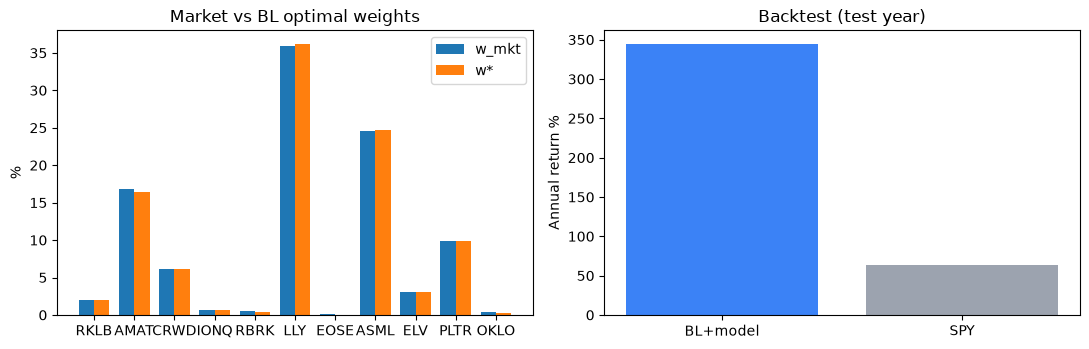

In [9]:
bt = run_backtest(stock_data, views, w_mkt, bench_close, max_weight=MAX_WEIGHT)
s, b = bt["strategy"], bt["benchmark"]
print(f"backtest grid {bt['grid_start']} -> {bt['grid_end']}  ({bt['n_rebalances']} rebalances)")

metrics = pd.DataFrame(
    {"BL+model": s, "SPY_buy_hold": b}).T[["ann_return", "ann_vol", "sharpe", "max_drawdown"]]
display(metrics.round(4))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x, bw = np.arange(len(tickers)), 0.38
ax[0].bar(x - bw/2, pct(w_mkt), bw, label="w_mkt")
ax[0].bar(x + bw/2, pct(res["w_star"]), bw, label="w*")
ax[0].set_xticks(x); ax[0].set_xticklabels(tickers); ax[0].set_ylabel("%")
ax[0].set_title("Market vs BL optimal weights"); ax[0].legend()
ax[1].bar(["BL+model", "SPY"], [s["ann_return"]*100, b["ann_return"]*100], color=["#3b82f6", "#9ca3af"])
ax[1].set_ylabel("Annual return %"); ax[1].set_title("Backtest (test year)")
plt.tight_layout(); plt.show()